<a href="https://colab.research.google.com/github/JacobKhay/L03-tree-stability/blob/main/Lab_3_Group_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---


# Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the notebook before beginning Phase 2.

Declaration: I completed this version without generative AI.

Student(s): Nithya Gopal, Jacob Khaykin, Heidi Williams

Date: 11/16/2026

Cloning into 'L03-tree-stability'...
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 17 (delta 4), reused 4 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (17/17), 76.28 KiB | 1.82 MiB/s, done.
Resolving deltas: 100% (4/4), done.
0
100 0.149 0.135
101 -0.104 0.079
102 0.183 0.27
103 0.192 0.315
104 0.068 0.107
                            100    101    102    103    104
age                       0.232  0.194  0.146  0.235  0.234
anaemia                   0.000  0.000  0.000  0.000  0.000
creatinine_phosphokinase  0.053  0.025  0.031  0.000  0.000
diabetes                  0.000  0.000  0.000  0.000  0.000
ejection_fraction         0.182  0.355  0.393  0.226  0.369
high_blood_pressure       0.033  0.011  0.029  0.055  0.000
platelets                 0.065  0.047  0.149  0.110  0.048
serum_creatinine          0.382  0.360  0.168  0.374  0.250
serum_sodium              0.038  0.00

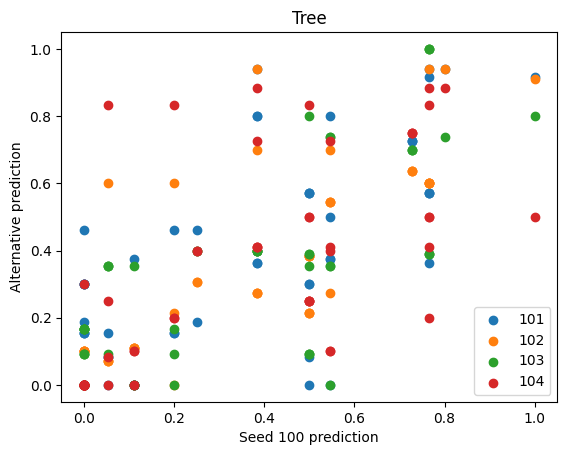

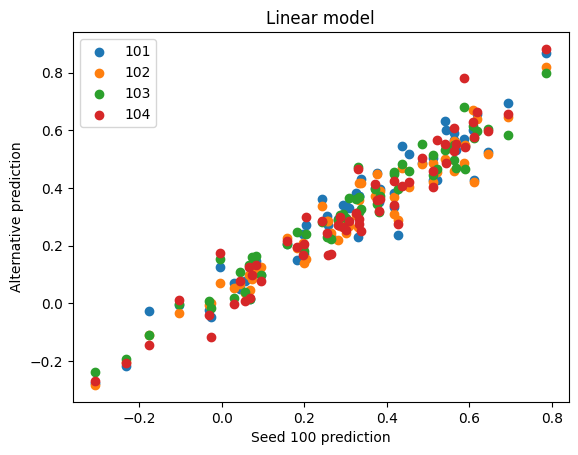

In [1]:
!git clone https://github.com/JacobKhay/L03-tree-stability.git

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

# Question 1

df = pd.read_csv("L03-tree-stability/data/heart_failure/heart_failure_clinical_records_dataset.csv")
print(df.isnull().sum().sum())
df = df.drop(columns="time")
for v in ["creatinine_phosphokinase", "serum_creatinine", "platelets"]:
    df[v] = np.arcsinh(df[v])
y = df["DEATH_EVENT"]
X = df.drop(columns="DEATH_EVENT")

# Question 2

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)
tree = DecisionTreeRegressor(min_samples_leaf=10, random_state=100).fit(X_train, y_train)
lm = LinearRegression().fit(X_train, y_train)
print(100, round(tree.score(X_test, y_test), 3), round(lm.score(X_test, y_test), 3))
tree_hat, lm_hat = tree.predict(X_test), lm.predict(X_test)

# Question 3

importance, coefs, tree_preds, lm_preds = {100: tree.feature_importances_}, {100: lm.coef_}, {}, {}
for s in [101, 102, 103, 104]:
    Xs_train, Xs_test, ys_train, ys_test = train_test_split(X, y, test_size=0.2, random_state=s)
    t = DecisionTreeRegressor(min_samples_leaf=10, random_state=s).fit(Xs_train, ys_train)
    m = LinearRegression().fit(Xs_train, ys_train)
    print(s, round(t.score(Xs_test, ys_test), 3), round(m.score(Xs_test, ys_test), 3))
    importance[s], coefs[s] = t.feature_importances_, m.coef_
    tree_preds[s], lm_preds[s] = t.predict(X_test), m.predict(X_test)
print(pd.DataFrame(importance, index=X.columns).round(3))
pd.DataFrame(coefs, index=X.columns).round(3)
import matplotlib.pyplot as plt

# Question 4a

for name, base, preds in [("Tree", tree_hat, tree_preds), ("Linear model", lm_hat, lm_preds)]:
    for s in preds:
        plt.scatter(base, preds[s], label=s)
    plt.xlabel("Seed 100 prediction")
    plt.ylabel("Alternative prediction")
    plt.title(name)
    plt.legend()
    plt.show()

**1.** There are no missing values. I dropped the time variable as the follow-up length depends on whether the patient died, so it leaks the outcome. I also applied arcsinh because  the variables creatinine_phosphokinase, serum_creatinine, and platelets were skewed.

**2.** Seed 100, 80/20 split. The Test R^2 for the tree and linear model are as follows: tree 0.149, linear model 0.135. Clearly, both are weak.

**3.** Seeds 101–104. The Test R^2 ranges from −0.10 to 0.19 for the tree and 0.08 to 0.32 for the linear model. The trees change a lot: the top feature switches between serum_creatinine and ejection_fraction (importance of each ranges about 0.17–0.39). Furthermore, features like platelets, serum_sodium, sex, and creatinine_phosphokinase drop in and out. While at the same time, the linear coefficients are steadier: age, ejection_fraction, and serum_creatinine barely move, though weak ones (platelets, smoking, anaemia, diabetes) change size and sometimes sign.

**4a.** For the trees, the predicted values appear to be reasonably dispersed, but share a generally positive alignment (lying loosely along the diagonal y=x). There is also a noticeable variance and step-like grouping, which represents the instability of the trees. However, for the linear models, the predictions are significantly tighter and cluster much closer along the diagonal line. This shows consistency and stability across the different train-test splits. Overall, the linear models exhibit much less variance across different training seeds compared to the decision tress.

In [6]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Question 4b
for s in [101, 102, 103, 104]:
    tree_corr = np.corrcoef(tree_hat, tree_preds[s])[0, 1]
    lm_corr = np.corrcoef(lm_hat, lm_preds[s])[0, 1]
    print(f"Seed {s} -> Tree Corr: {tree_corr:.2f} | LM Corr: {lm_corr:.2f}")

# Question 4c
def print_reg_summary(base, alt, name):
    lr = LinearRegression().fit(base.reshape(-1, 1), alt)
    print(f"{name} -> Intercept: {lr.intercept_:.2f}, Slope: {lr.coef_[0]:.2f}, R2: {lr.score(base.reshape(-1,1), alt):.2f}")

for s in [101, 102, 103, 104]:
    print(f"\nAlternative Seed {s}:")
    print_reg_summary(tree_hat, tree_preds[s], "  Tree")
    print_reg_summary(lm_hat, lm_preds[s], "  Linear Model")

Seed 101 -> Tree Corr: 0.74 | LM Corr: 0.96
Seed 102 -> Tree Corr: 0.84 | LM Corr: 0.97
Seed 103 -> Tree Corr: 0.77 | LM Corr: 0.98
Seed 104 -> Tree Corr: 0.70 | LM Corr: 0.96

Alternative Seed 101:
  Tree -> Intercept: 0.10, Slope: 0.75, R2: 0.55
  Linear Model -> Intercept: 0.04, Slope: 0.91, R2: 0.92

Alternative Seed 102:
  Tree -> Intercept: 0.05, Slope: 0.82, R2: 0.71
  Linear Model -> Intercept: 0.03, Slope: 0.89, R2: 0.94

Alternative Seed 103:
  Tree -> Intercept: 0.07, Slope: 0.74, R2: 0.59
  Linear Model -> Intercept: 0.05, Slope: 0.89, R2: 0.95

Alternative Seed 104:
  Tree -> Intercept: 0.08, Slope: 0.71, R2: 0.49
  Linear Model -> Intercept: 0.01, Slope: 0.96, R2: 0.93


**4b.** The decision tree predictions show a moderately high correlation with the base model, ranging between 0.70 and 0.84 across the different seeds. In contrast, the linear model predictions demonstrate extremely high correlation values ranging from 0.96 to 0.98. This indicates that while both model types remain positively correlated across different random splits, the linear models show a significantly superior level of stability.

**4c.** For the decision trees, running a linear regresion of the alternative predictions on the base model results in a small positive intercept (0.05 to 0.10), a slope less than one (0.71 to 0.82), and a moderate R-squared (0.49 to 0.71). For the linear models, the regressions result in intercepts very close to 0 (0.01 to 0.05), slopes very close to one (0.89 to 0.96), and significantly high R-squared values (0.92 to 0.95). This proves that the linear models' predictions are nearly identical across splits, whereas the tree predictions are more variable.

**5.** Yes, the linear models are highly consistent across train/test splits, producing both highly stable coefficients and very consistent final test predictions. In contrast, the decision trees do not show this consistency; their internal structures and feature importances change drastically from seed to seed, resulting in much less stable predictions.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]